## Data

Generate a sample of two random variables x and y, for which the variance of y depends on the values of x. The generated samples are noted $(x_1, ..., x_n)$ and $(y_1, ..., y_n)$.

In [40]:
import numpy as np
import torch

np.random.seed(1) # for reproducibility

n = 100
rng = np.random.default_rng()
sig_eps = 0.5


x = np.linspace(0, 10, n)
y = x + rng.normal(0, sig_eps, n)



#sig = np.abs(x)

x = torch.tensor(x, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)


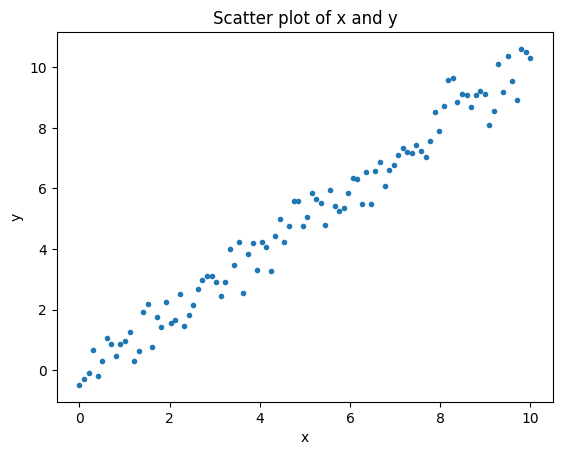

In [41]:
import matplotlib.pyplot as plt

plt.scatter(x, y, marker='.')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.show()

## Goal

The goal is to build a neural network to predict the conditional distribution $p(y∣x=x_i), \forall i$.

In a first step, use a parametric approach, where the conditional distribution is supposed to follow a Gaussian distribution:

1/ $N(ax+b,\sigma^2), \forall i$

2/ $N(ax+b,\sigma_i^2)$, depending on the index $i$

In a second step, use a nonparametric approach, where for all index $i$, compute different quantiles such as $Q_{5}$, $Q_{50}$ (median), and $Q_{95}$.

In [ ]:

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(1,1)
        self.log_var = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        mu = self.l1(x)          
        var = torch.exp(self.log_var).expand_as(mu)    
        return mu, var



In [43]:
def nll(y, mu, var):
    return (0.5*torch.log(var) + (y - mu)**2 / (2*var)).mean()

model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for t in range(2000):
    mu, var = model(x)
    loss = nll(y, mu, var)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if t % 200 == 199:
        print(t, loss.item())

199 0.3181326687335968
399 0.13256245851516724
599 -0.05601547285914421
799 -0.1521625965833664
999 -0.17487694323062897
1199 -0.17737917602062225
1399 -0.1775117814540863
1599 -0.17751555144786835
1799 -0.17751558125019073
1999 -0.17751556634902954


sigma moyen predit : 0.5078781247138977  (vrai sigma : 0.5 )
points dans mu +- 2 sigma : 0.949999988079071
tensor([1.0410], grad_fn=<SelectBackward0>) tensor(-0.2131, grad_fn=<SelectBackward0>)


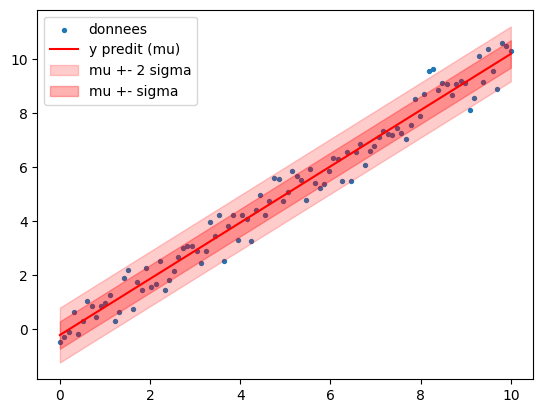

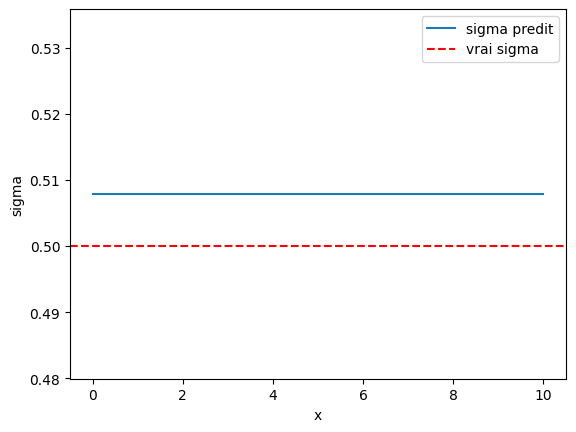

In [45]:
with torch.no_grad():
    mu, var = model(x)
sigma_pred = torch.sqrt(var)

print("sigma moyen predit :", sigma_pred.mean().item(), " (vrai sigma :", sig_eps, ")")

dedans = (torch.abs(y - mu) < 2*sigma_pred).float().mean()
print("points dans mu +- 2 sigma :", dedans.item())

print(model.l1.weight[0], model.l1.bias[0])

plt.scatter(x, y, s=8, label='donnees')
plt.plot(x, mu, 'r', label='y predit (mu)')
plt.fill_between(x[:,0], (mu - 2*sigma_pred)[:,0], (mu + 2*sigma_pred)[:,0],
                 alpha=0.2, color='r', label='mu +- 2 sigma')
plt.fill_between(x[:,0], (mu - sigma_pred)[:,0], (mu + sigma_pred)[:,0],
                 alpha=0.3, color='r', label='mu +- sigma')
plt.legend()
plt.show()

plt.plot(x, sigma_pred, label='sigma predit')
plt.axhline(sig_eps, color='r', linestyle='--', label='vrai sigma')
plt.xlabel('x')
plt.ylabel('sigma')
plt.legend()
plt.show()

## Partie 2 : variance qui dépend du point, $N(ax+b, \sigma_i^2)$

In [48]:
x = np.random.normal(0, 1, 1000)
x = np.sort(x)
y = x + np.random.normal(0, np.abs(x), 1000)

sig = np.abs(x)

x = torch.tensor(x, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

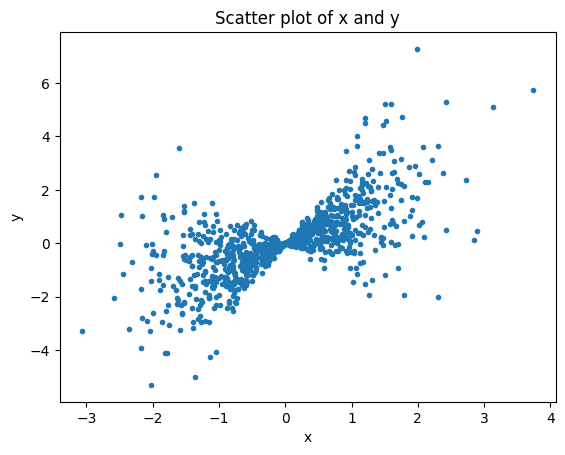

In [49]:
plt.scatter(x, y, marker='.')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.show()

In [50]:
class MLP_sigma_i(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(1,32)
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(32,2)

    def forward(self, x):
        x = self.l1(x)
        x = self.relu(x)
        x = self.l2(x)
        mu = x[:, 0:1]
        var = torch.exp(x[:, 1:2])       # une variance differente pour chaque x
        return mu, var


In [51]:
torch.manual_seed(0)
model = MLP_sigma_i()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for t in range(3000):
    mu, var = model(x)
    loss = nll(y, mu, var)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if t % 500 == 499:
        print(t, loss.item())

499 -0.10680587589740753
999 -0.14061734080314636
1499 -0.14931488037109375
1999 -0.15582606196403503
2499 -0.1580098420381546
2999 -0.1580965518951416


erreur moyenne sur sigma : 0.6354756061061763
points dans mu +- sigma   : 0.6980000138282776
points dans mu +- 2 sigma : 0.953000009059906


/var/folders/9z/fdfchvs93mxbbpctnzdc8rc40000gn/T/ipykernel_2313/2776871347.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print("erreur moyenne sur sigma :", torch.abs(sigma_pred - sig).mean().item())


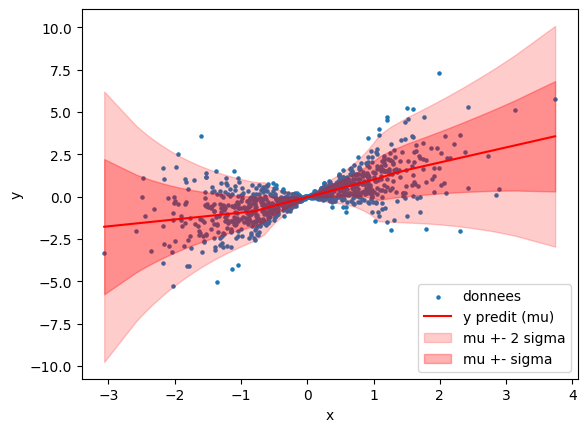

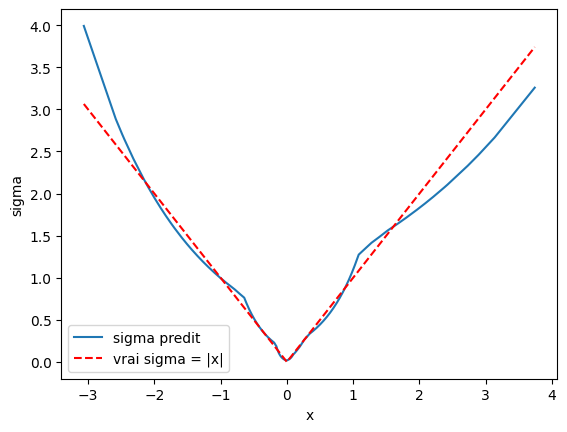

In [52]:
with torch.no_grad():
    mu, var = model(x)
sigma_pred = torch.sqrt(var)

print("erreur moyenne sur sigma :", torch.abs(sigma_pred - sig).mean().item())
print("points dans mu +- sigma   :", (torch.abs(y - mu) < sigma_pred).float().mean().item())
print("points dans mu +- 2 sigma :", (torch.abs(y - mu) < 2*sigma_pred).float().mean().item())

plt.scatter(x, y, s=5, label='donnees')
plt.plot(x, mu, 'r', label='y predit (mu)')
plt.fill_between(x[:,0], (mu - 2*sigma_pred)[:,0], (mu + 2*sigma_pred)[:,0],
                 alpha=0.2, color='r', label='mu +- 2 sigma')
plt.fill_between(x[:,0], (mu - sigma_pred)[:,0], (mu + sigma_pred)[:,0],
                 alpha=0.3, color='r', label='mu +- sigma')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

plt.plot(x, sigma_pred, label='sigma predit')
plt.plot(x, sig, 'r--', label='vrai sigma = |x|')
plt.xlabel('x')
plt.ylabel('sigma')
plt.legend()
plt.show()

## Partie 3 : Approche non-paramétrique qui sort $Q_{5}$, $Q_{50}$, et $Q_{95}$

In [53]:
tau = torch.tensor([0.05, 0.5, 0.95]) 

In [54]:
class MLP_quantiles(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(1,32)
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(32,3)

    def forward(self, x):
        x = self.l1(x)
        x = self.relu(x)
        q = self.l2(x)
        return q

In [55]:
def pinball(y, q, tau):
    r = y - q
    return torch.max(tau*r, (tau - 1)*r).mean()

In [56]:
torch.manual_seed(0)
model = MLP_quantiles()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for t in range(3000):
    q = model(x)
    loss = pinball(y, q, tau)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if t % 500 == 499:
        print(t, loss.item())

499 0.15614472329616547
999 0.15543587505817413
1499 0.15514780580997467
1999 0.15470826625823975
2499 0.15432977676391602
2999 0.15419435501098633


Q5 : 5.1 % des points en dessous (attendu 5 %)
Q50 : 48.7 % des points en dessous (attendu 50 %)
Q95 : 93.8 % des points en dessous (attendu 95 %)


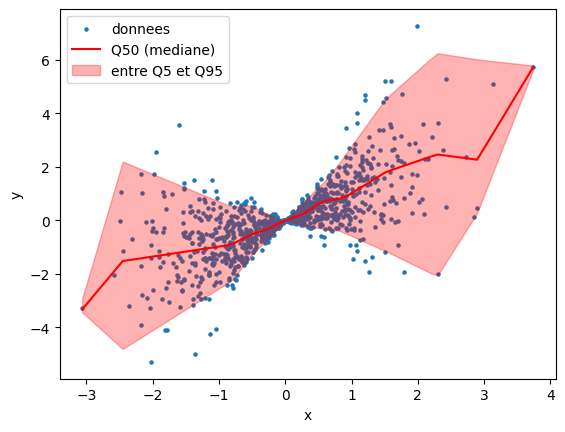

In [57]:
with torch.no_grad():
    q = model(x)

for k in range(3):
    dessous = (y < q[:, k:k+1]).float().mean().item()
    print(f"Q{int(tau[k]*100)} : {dessous*100:.1f} % des points en dessous (attendu {tau[k]*100:.0f} %)")

plt.scatter(x, y, s=5, label='donnees')
plt.plot(x, q[:, 1], 'r', label='Q50 (mediane)')
plt.fill_between(x[:,0], q[:, 0], q[:, 2], alpha=0.3, color='r', label='entre Q5 et Q95')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [59]:
tau = torch.tensor([0.01,0.5, 0.99])
for t in range(3000):
    q = model(x)
    loss = pinball(y, q, tau)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if t % 500 == 499:
        print(t, loss.item())

499 0.11487317085266113
999 0.11467072367668152
1499 0.11456767469644547
1999 0.11436674743890762
2499 0.1141810268163681
2999 0.11424410343170166


Q1 : 0.9 % des points en dessous (attendu 1 %)
Q50 : 48.1 % des points en dessous (attendu 50 %)
Q99 : 98.6 % des points en dessous (attendu 99 %)


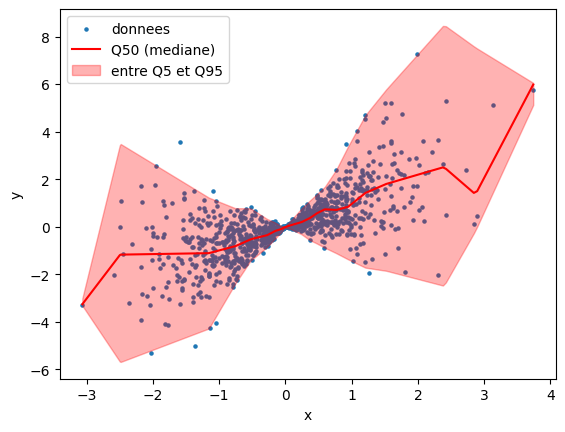

In [60]:
with torch.no_grad():
    q = model(x)

for k in range(3):
    dessous = (y < q[:, k:k+1]).float().mean().item()
    print(f"Q{int(tau[k]*100)} : {dessous*100:.1f} % des points en dessous (attendu {tau[k]*100:.0f} %)")

plt.scatter(x, y, s=5, label='donnees')
plt.plot(x, q[:, 1], 'r', label='Q50 (mediane)')
plt.fill_between(x[:,0], q[:, 0], q[:, 2], alpha=0.3, color='r', label='entre Q5 et Q95')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()